In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import dendrogram, linkage

In [2]:
random_state = 42
X, y = make_blobs(n_samples=500, centers=4, random_state=random_state)
print("X:", X.shape, "| gerçek küme boyutları:", np.bincount(y))

X: (500, 2) | gerçek küme boyutları: [125 125 125 125]


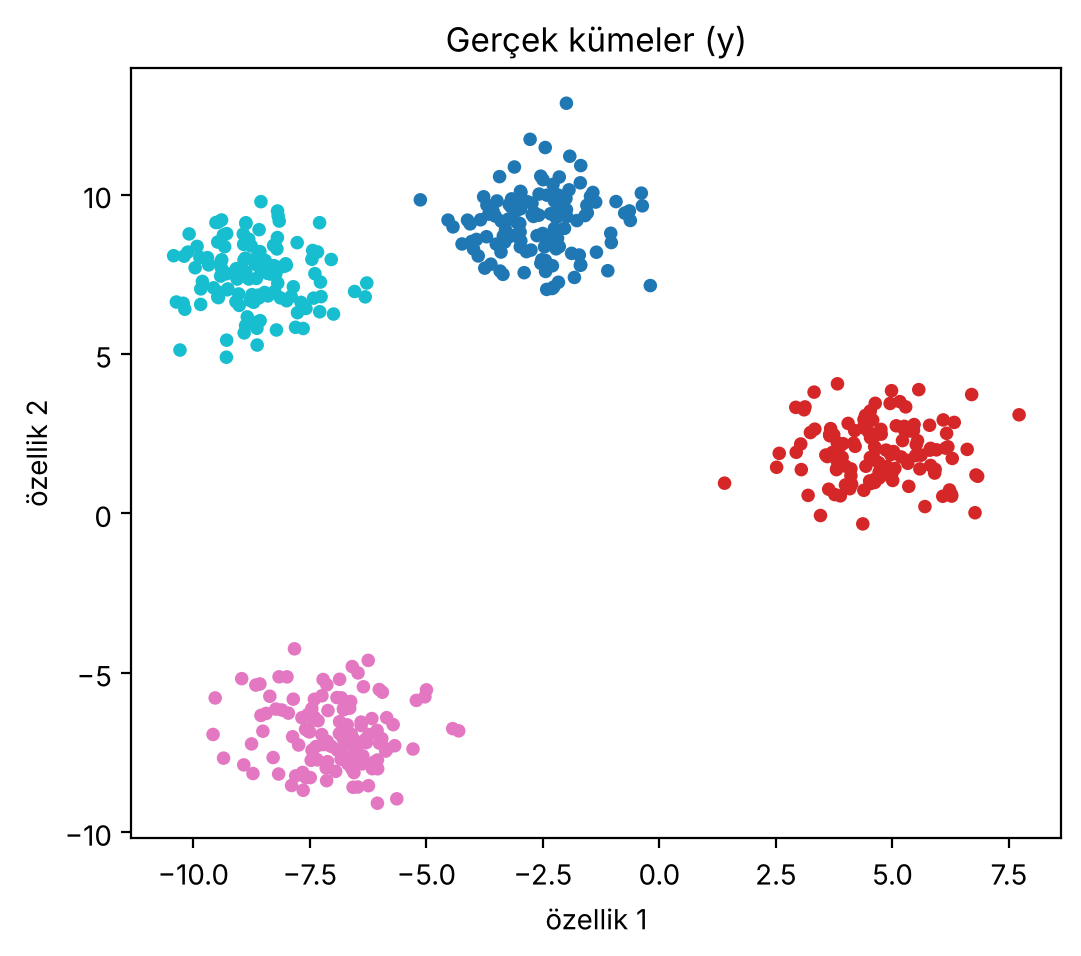

In [3]:
plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="tab10", s=15)
plt.title("Gerçek kümeler (y)")
plt.xlabel("özellik 1")
plt.ylabel("özellik 2")
plt.show()

In [4]:
kmeans_2 = KMeans(n_clusters=2, random_state=random_state).fit(X)
y_pred = kmeans_2.predict(X)

counts = np.bincount(y_pred)
print("Küme boyutları:", counts, "| oran:", counts.max() / counts.min())
print("Merkezler:")
print(kmeans_2.cluster_centers_.round(2))
print("Inertia:", round(kmeans_2.inertia_, 1))

Küme boyutları: [375 125] | oran: 3.0
Merkezler:
[[-2.19  6.16]
 [-7.   -6.9 ]]
Inertia: 15737.1


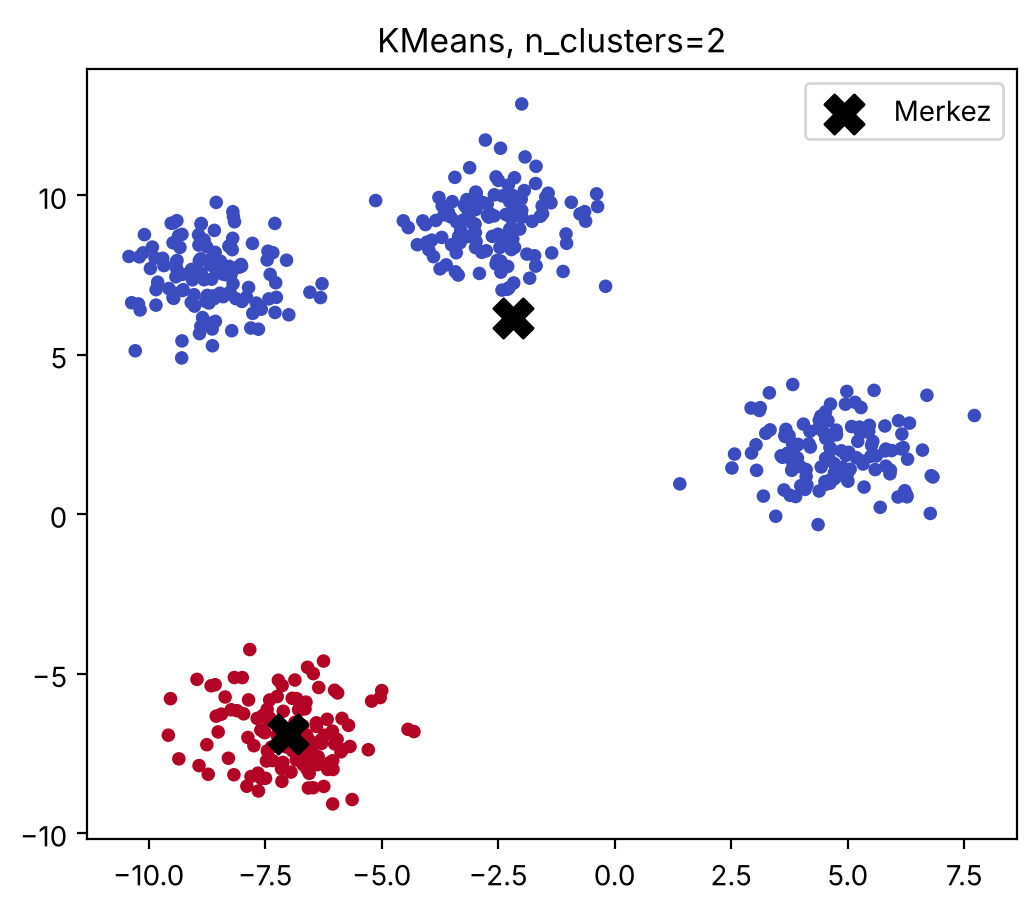

tahmin    0    1
gerçek          
0       125    0
1       125    0
2         0  125
3       125    0


In [5]:
plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=y_pred, cmap="coolwarm", s=15)
plt.scatter(*kmeans_2.cluster_centers_.T, c="black", marker="X", s=200, label="Merkez")
plt.title("KMeans, n_clusters=2")
plt.legend()
plt.show()

print(pd.crosstab(y, y_pred, rownames=["gerçek"], colnames=["tahmin"]))

In [6]:
wcss = []
silhouettes = []
clusters = list(range(1, 11))
for k in clusters:
    model = KMeans(n_clusters=k, random_state=random_state).fit(X)
    wcss.append(model.inertia_)
    silhouettes.append(silhouette_score(X, model.labels_) if k > 1 else np.nan)

pd.DataFrame({"k": clusters, "inertia": wcss, "silhouette": silhouettes}).round(3)

,k,inertia,silhouette
0,1,33903.904,NaN
1,2,15737.084,0.596
2,3,3426.257,0.761
3,4,948.890,0.791
4,5,861.765,0.688
5,6,773.657,0.560
6,7,686.854,0.471
7,8,639.015,0.443
8,9,599.309,0.429
9,10,512.292,0.345


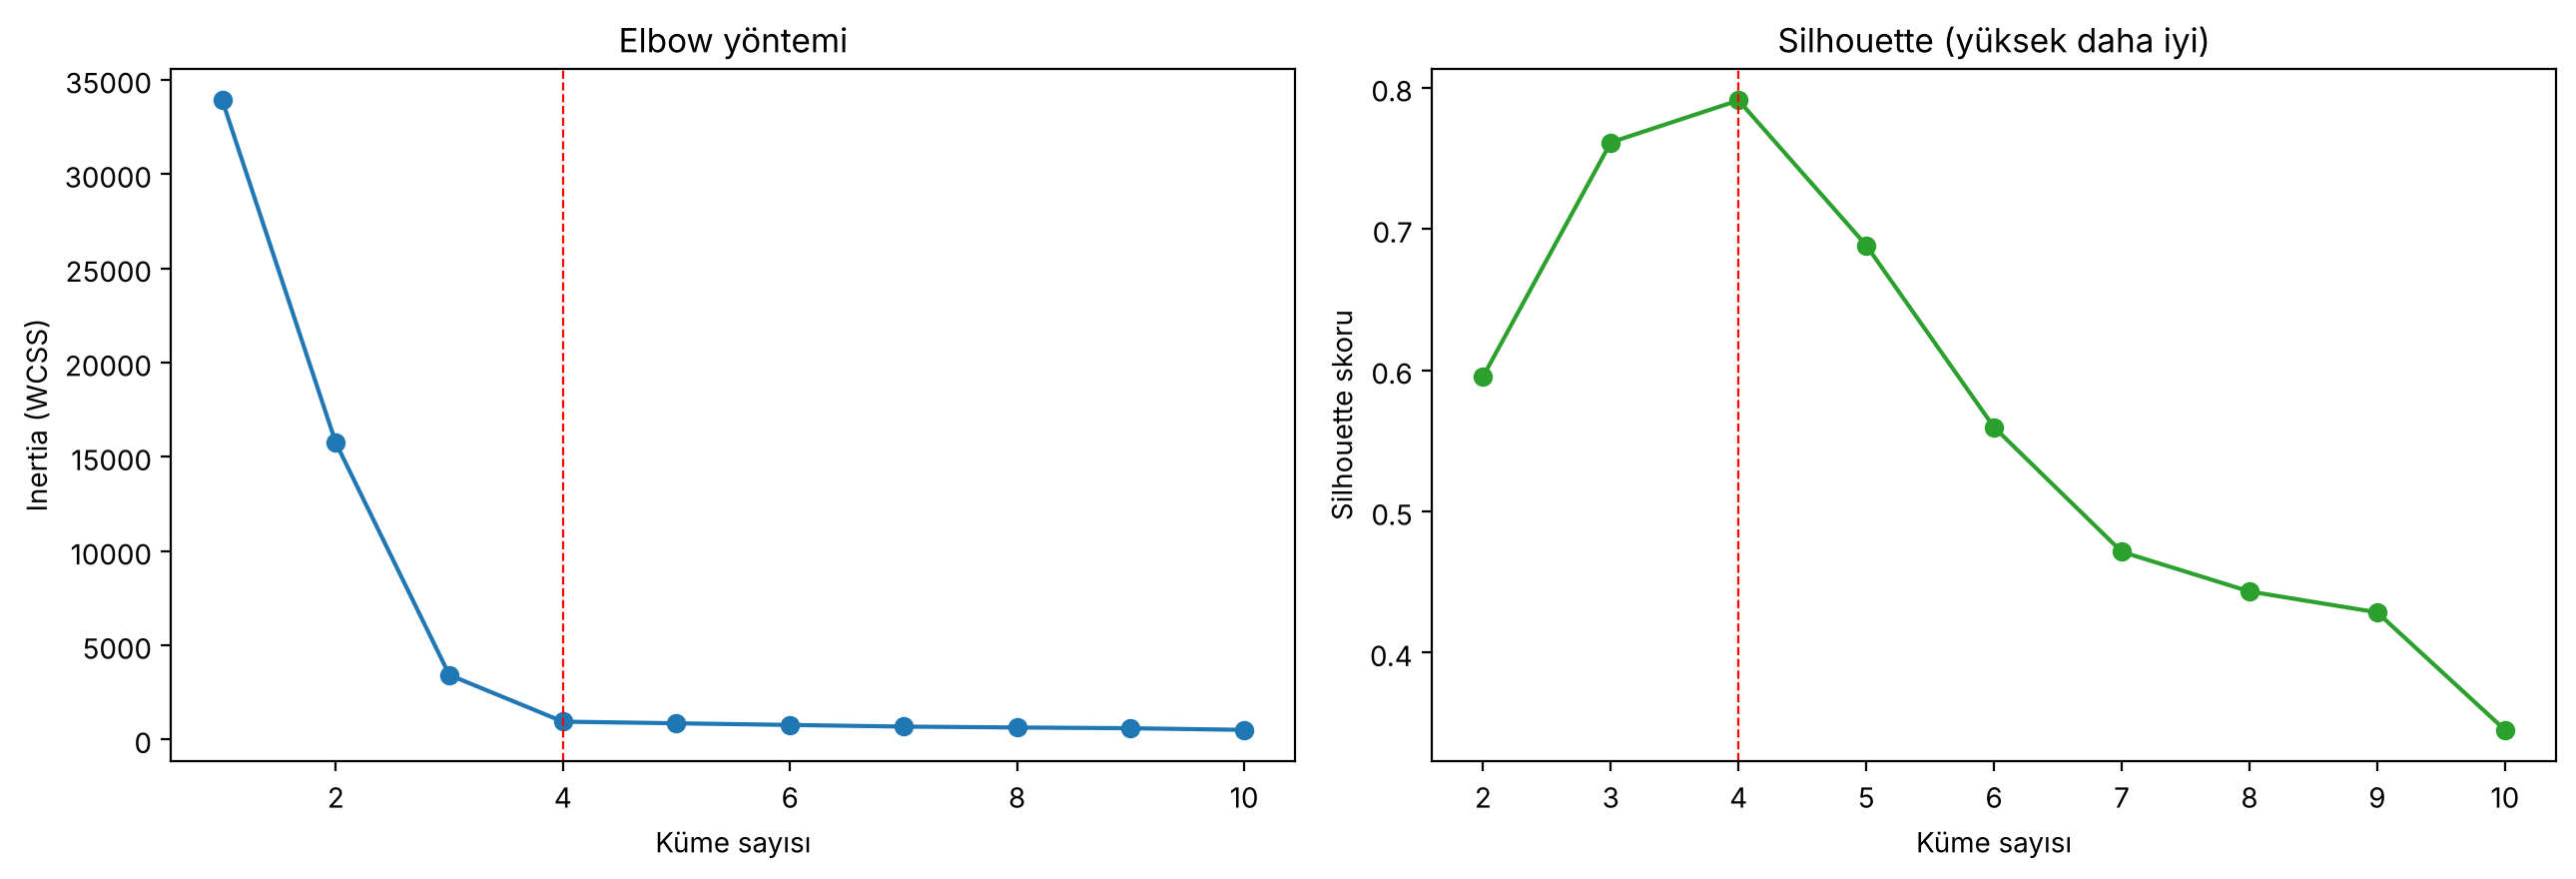

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(clusters, wcss, marker="o")
axes[0].axvline(4, color="red", linestyle="--", linewidth=0.8)
axes[0].set_xlabel("Küme sayısı")
axes[0].set_ylabel("Inertia (WCSS)")
axes[0].set_title("Elbow yöntemi")
axes[1].plot(clusters[1:], silhouettes[1:], marker="o", color="tab:green")
axes[1].axvline(4, color="red", linestyle="--", linewidth=0.8)
axes[1].set_xlabel("Küme sayısı")
axes[1].set_ylabel("Silhouette skoru")
axes[1].set_title("Silhouette (yüksek daha iyi)")
plt.tight_layout()
plt.show()

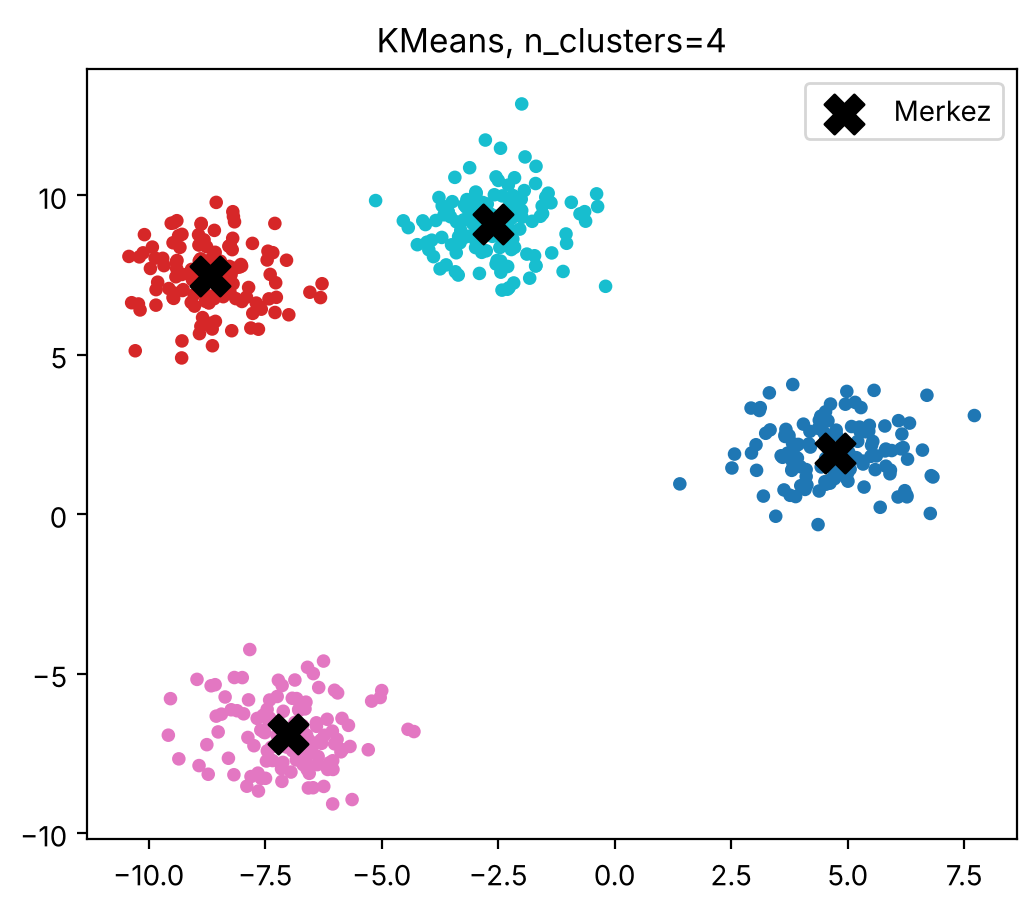

Küme boyutları: [125 125 125 125]
Adjusted Rand Index (gerçek kümelerle uyum): 1.0
tahmin    0    1    2    3
gerçek                    
0         0    0    0  125
1       125    0    0    0
2         0    0  125    0
3         0  125    0    0


In [8]:
kmeans_4 = KMeans(n_clusters=4, random_state=random_state).fit(X)
y_pred = kmeans_4.predict(X)

plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=y_pred, cmap="tab10", s=15)
plt.scatter(*kmeans_4.cluster_centers_.T, c="black", marker="X", s=200, label="Merkez")
plt.title("KMeans, n_clusters=4")
plt.legend()
plt.show()

print("Küme boyutları:", np.bincount(y_pred))
print("Adjusted Rand Index (gerçek kümelerle uyum):", round(adjusted_rand_score(y, y_pred), 4))
print(pd.crosstab(y, y_pred, rownames=["gerçek"], colnames=["tahmin"]))

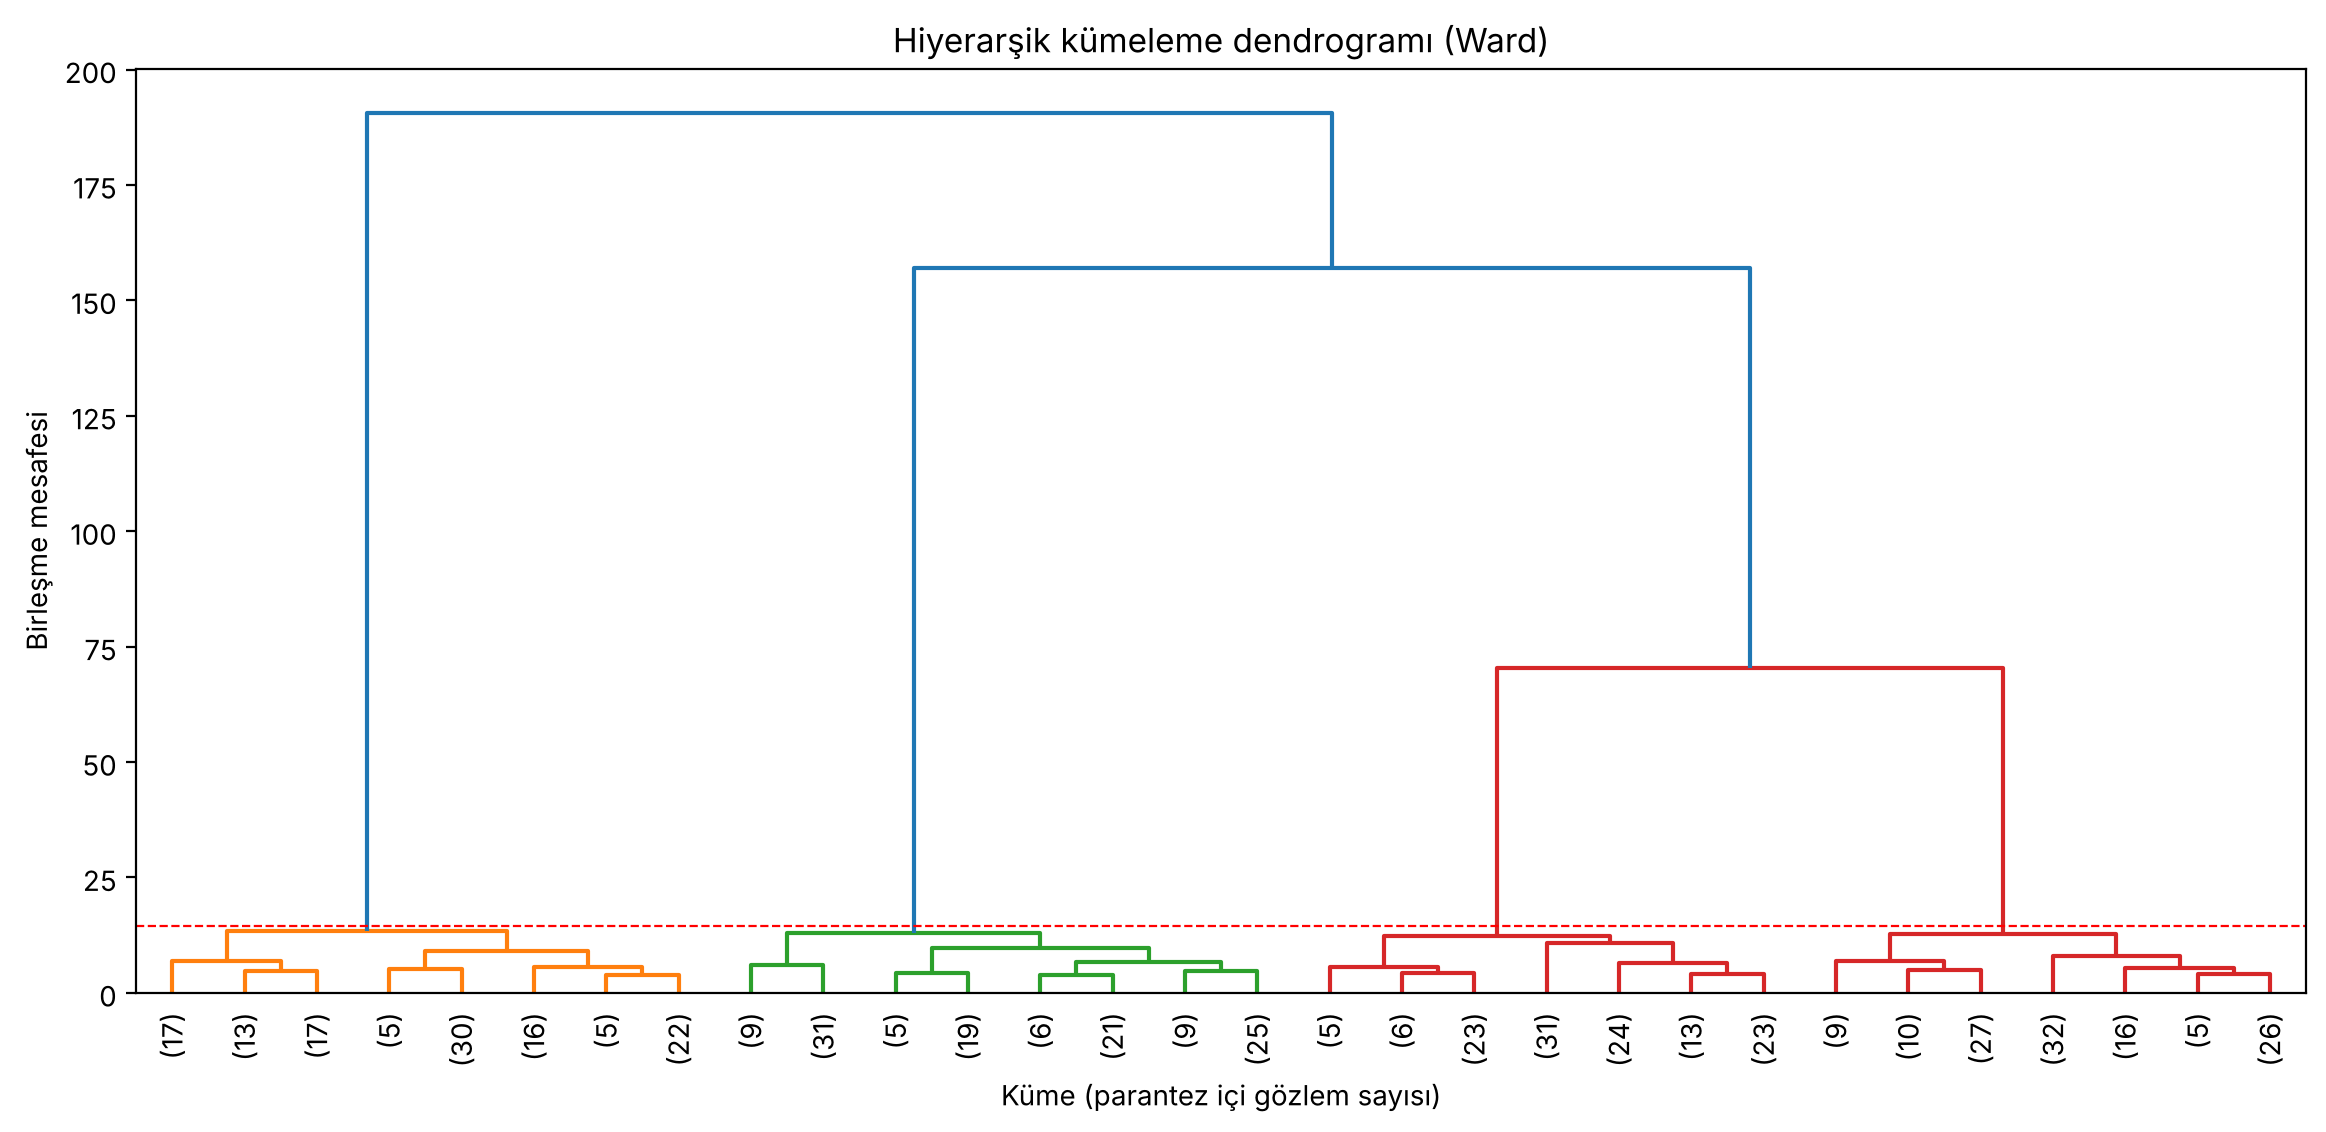

Son 5 birleşme mesafesi: [ 12.9  13.5  70.4 156.9 190.6]


In [9]:
Z = linkage(X, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90)
plt.axhline(Z[-4, 2] + 1, color="red", linestyle="--", linewidth=0.8)
plt.title("Hiyerarşik kümeleme dendrogramı (Ward)")
plt.xlabel("Küme (parantez içi gözlem sayısı)")
plt.ylabel("Birleşme mesafesi")
plt.show()

print("Son 5 birleşme mesafesi:", Z[-5:, 2].round(1))

## Sonuç

- **Veri:** `make_blobs` ile 500 gözlem, 2 özellik, her biri 125 gözlemli 4 küme. Grafikte 4 küme açıkça ayrılıyor; biri diğer üçünden uzakta.

- **k = 2:** KMeans kendisinden istenen şeyi yaptı ve veriyi iki kümeye böldü: uzaktaki küme tek başına (125 gözlem), diğer üç küme tek bir kümede (375 gözlem), oran 3. Inertia 15.737. KMeans gerçek yapıyı bilmiyor, yalnızca verilen merkez sayısına göre noktaları en yakın merkeze atıyor.

- **Elbow yöntemi:** Inertia k = 1'de 33.904, k = 2'de 15.737, k = 3'te 3.426, k = 4'te 949. Sonrasında düşüş neredeyse duruyor (k = 5'te 862, k = 10'da 512). Dirsek açıkça k = 4'te. Silhouette skoru da en yüksek değerine k = 4'te ulaşıyor (0.791; k = 3'te 0.761, k = 5'te 0.688), yani iki yöntem aynı sonucu veriyor.

- **k = 4:** Her küme 125 gözlem aldı ve tahminler gerçek kümelerle birebir örtüştü (Adjusted Rand Index = 1.0). Etiket numaraları farklı ama bu önemli değil; KMeans küme isimlerini değil grupları buluyor.

- **Hiyerarşik kümeleme:** Ward bağlantılı dendrogramda son birleşmelerin mesafeleri 12.9, 13.5, 70.4, 156.9 ve 190.6. 13.5'ten 70.4'e büyük bir sıçrama var; dendrogram bu noktadan kesilince yine 4 küme çıkıyor. Ward yöntemi de KMeans gibi küme içi varyansı en aza indirdiği için iki yöntemin aynı sonuca varması beklenen bir durum.

- **Sınırlılık:** Bu veri, birbirinden iyi ayrılmış yuvarlak kümelerle bilerek kolay seçildi. Gerçek veride kümeler iç içe, farklı boyutlarda veya yuvarlak olmayan şekillerde olduğunda elbow noktası bu kadar net olmaz ve KMeans'in yuvarlak küme varsayımı yanıltabilir.